In [60]:
import matplotlib.pyplot as plt
import numpy as np
import random
import seaborn as sns

In [4]:
## First: need to numerically find the root for R*

In [6]:
def bisection(f, a, b, tol):
    p1 = a
    p2 = b
    while p2 - p1 > tol:
        mid = .5*(p1 + p2)
        if f(p1) * f(mid) < 0:
            p2 = mid
        else:
            p1 = mid
    return .5*(p1 + p2)

In [16]:
p_H = .5
rho = .5
tau = 5
def R(T):
    num = p_H*(1-np.e**(-rho*T))
    denom = p_H/rho * (1-np.e**(-rho*T)) + (1-p_H)*T + tau

    return num/denom
def l(T):
    num = rho*p_H*np.e**(-rho*T)
    denom = p_H*np.e**(-rho*T) + (1-p_H)

    return num/denom
def w(T):
    return R(T) - l(T)

In [22]:
root = bisection(w, 0, 10, 1e-12)
root

4.1814348103108046

In [24]:
R(root)

0.05500115972326258

In [42]:
def sim_patches(num_patches, p_high, rho, tau, T):
    # a patch is "high" with probability p_high"
    # the animal looks until time T, then gives up
    
    time = 0
    reward = 0

    for p in range(1,num_patches+1):
        q = random.random()
        if q > p_high:
            # empty patch; spend time T, then leave. no reward
            time += T + tau
        
        else:
            # full patch; search with exponential time:
            find_time = random.expovariate(rho)
            if find_time < T:
                # we found the food!
                time += find_time + tau
                reward += 1

            else: 
                # we didn't find the food, we gave up. no reward
                time += T + tau

    return time, reward, reward/time

In [44]:
_, _, rate2 = sim_patches(4000, .5, .5, 5, 2)
_, _, rate_star = sim_patches(4000, .5, .5, 5, root)
_, _, rate10 = sim_patches(4000, .5, .5, 5, 10)

In [64]:
rate_list = [rate2, rate_star, rate10]
rate_list2 = [R(2), R(root), R(10)]

print(rate_list)
print(rate_list2)

[0.04707977155205551, 0.055789541291348325, 0.044718768351963346]
[0.04765599126414329, 0.05500115972326258, 0.04517594723987209]


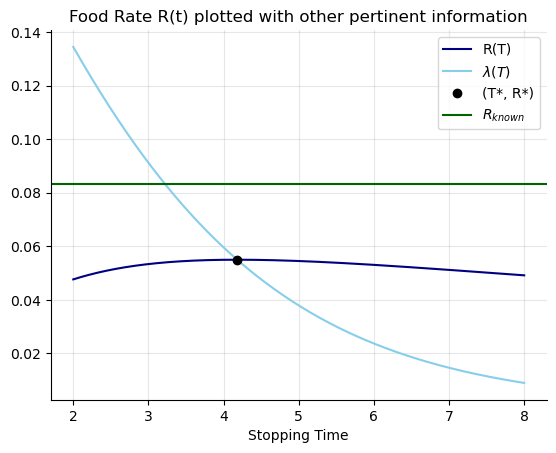

In [69]:
T_vals = np.linspace(2, 8, 300)
plt.plot(T_vals, R(T_vals), label = "R(T)", color = "navy")
plt.plot(T_vals, l(T_vals), label = r"$\lambda(T)$", color = "skyblue")
plt.plot(root, R(root), 'o', label = "(T*, R*)", color = "black")
plt.axhline(y = 1/12, label = r"$R_{known}$", color = "darkgreen")
plt.legend()
plt.grid(alpha = .3)
sns.despine()
plt.xlabel("Stopping Time")
plt.title("Food Rate R(t) plotted with other pertinent information")
plt.savefig("patchgraph", dpi = 300, bbox_inches = "tight")
plt.show()